Total samples in metadata:                          349696
Unique texts with multiple emotions:                263
Total samples with multiple emotions:               3548
Samples before duplicate removal:                   346148
Duplicates removed:                                 211197
Samples after duplicate removal:                    134951

Distribution across emotion classes:
          Count  Percent
Emotion                 
Neutral   30982    22.96
Anger     28057    20.79
Sadness   26687    19.78
Joy       24997    18.52
Surprise  24228    17.95


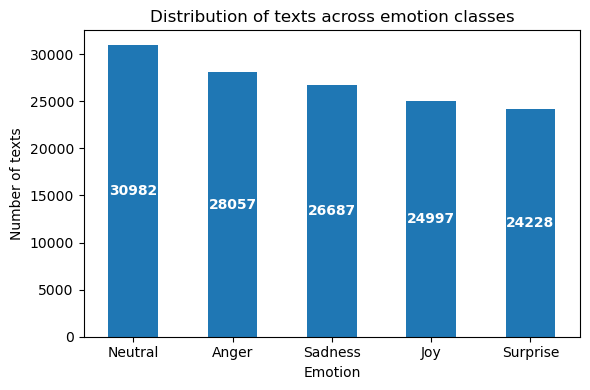

In [1]:
#Preparing dataset for emotion classification
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from collections import Counter
from wordcloud import WordCloud

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import FastText
from sentence_transformers import SentenceTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv("metadata.csv", sep="|", header=None, names=["Path", "Speaker", "Text"], dtype=str, encoding="utf-8")

#Extracting emotion letters and mapping to full English names
df["Emotion"] = df["Path"].str.split("/").str[1]
emotion_mapping = {
    "D": "Joy",
    "L": "Sadness",
    "N": "Surprise",
    "P": "Anger",
    "Z": "Neutral"
}
df["Emotion"] = df["Emotion"].map(emotion_mapping)

df = df[["Text", "Emotion"]].dropna()
df["Text"] = df["Text"].str.replace(r"\s+", " ", regex=True).str.strip()
total_rows = len(df)

#Texts with multiple emotion labels
labels_per_text = df.groupby("Text")["Emotion"].transform("nunique")
multi = df[labels_per_text > 1]
df = df[labels_per_text == 1]

#Removing duplicates
before_dedup = len(df)
df = df.drop_duplicates(subset="Text")
after_dedup = len(df)

df.to_csv("emo_text_dataset.csv", index=False, encoding="utf-8")

print(f"Total samples in metadata:                          {total_rows}")
print(f"Unique texts with multiple emotions:                {multi['Text'].nunique()}")
print(f"Total samples with multiple emotions:               {len(multi)}")
print(f"Samples before duplicate removal:                   {before_dedup}")
print(f"Duplicates removed:                                 {before_dedup - after_dedup}")
print(f"Samples after duplicate removal:                    {after_dedup}\n")

distribution = df["Emotion"].value_counts().to_frame("Count")
distribution["Percent"] = (distribution["Count"] / after_dedup * 100).round(2)
print("Distribution across emotion classes:")
print(distribution)

ax = distribution["Count"].plot(kind="bar", rot=0, figsize=(6, 4))
ax.bar_label(ax.containers[0], label_type="center", color="white", fontweight="bold")
ax.set_title("Distribution of texts across emotion classes")
ax.set_xlabel("Emotion")
ax.set_ylabel("Number of texts")
plt.tight_layout()
plt.show()

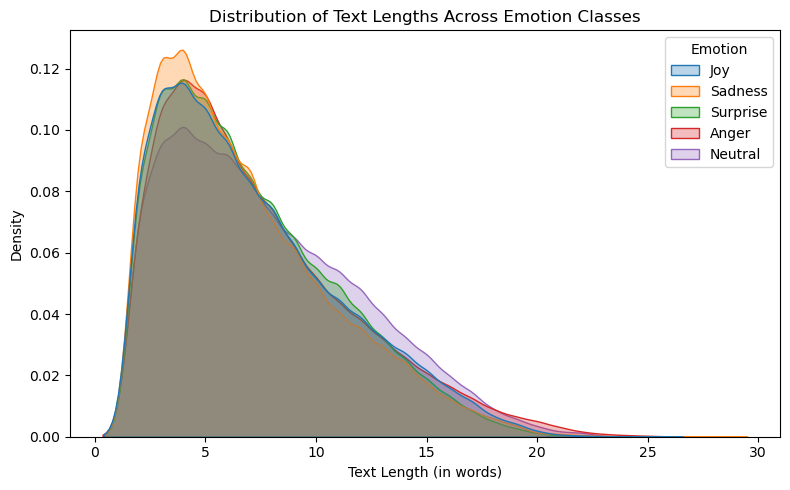


--- Top 10 Most Frequent Words for Emotion: Anger ---
[('niekas', 781), ('dabar', 741), ('viskas', 692), ('norėti', 620), ('nebūti', 545), ('negalėti', 476), ('ten', 452), ('sakyti', 406), ('kartas', 396), ('darbas', 370)]

--- Top 10 Most Frequent Words for Emotion: Joy ---
[('džiaugsmas', 1522), ('labai', 1156), ('diena', 1126), ('gyvenimas', 1068), ('širdis', 840), ('laimė', 713), ('naujas', 637), ('metai', 587), ('vaikas', 556), ('geras', 555)]

--- Top 10 Most Frequent Words for Emotion: Neutral ---
[('miestas', 1040), ('vilnius', 899), ('metai', 777), ('labai', 739), ('lietuva', 713), ('nebūti', 693), ('sakyti', 690), ('darbas', 665), ('vieta', 565), ('teatras', 556)]

--- Top 10 Most Frequent Words for Emotion: Sadness ---
[('labai', 900), ('niekas', 857), ('gyvenimas', 699), ('dabar', 500), ('liūdna', 482), ('diena', 473), ('nebūti', 461), ('metai', 450), ('atrodyti', 448), ('viskas', 416)]

--- Top 10 Most Frequent Words for Emotion: Surprise ---
[('neįtikėtinti', 747), ('pat

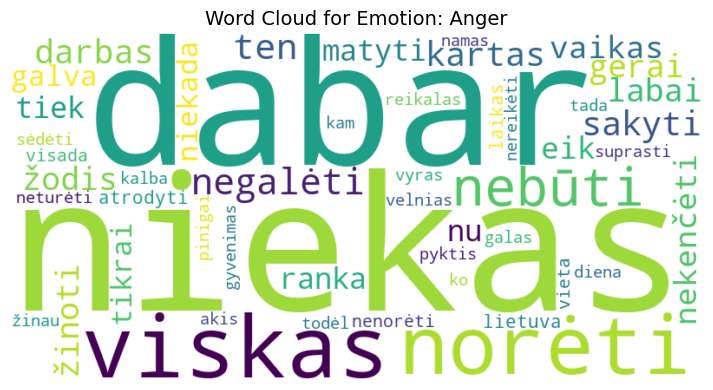

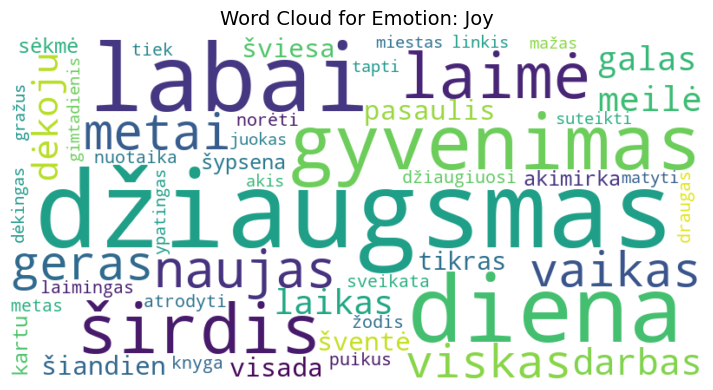

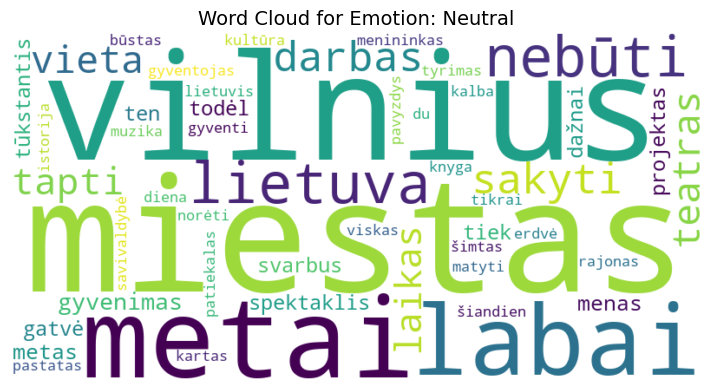

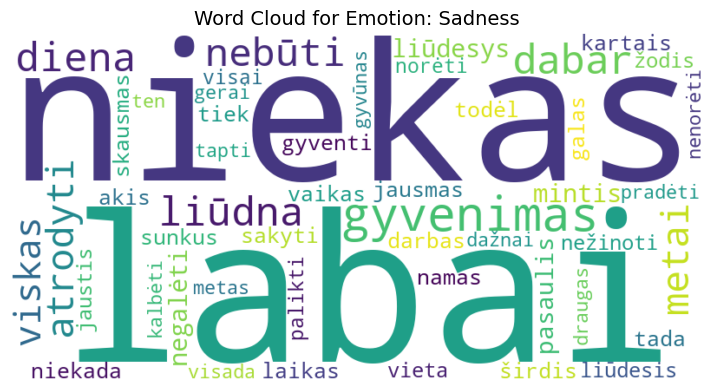

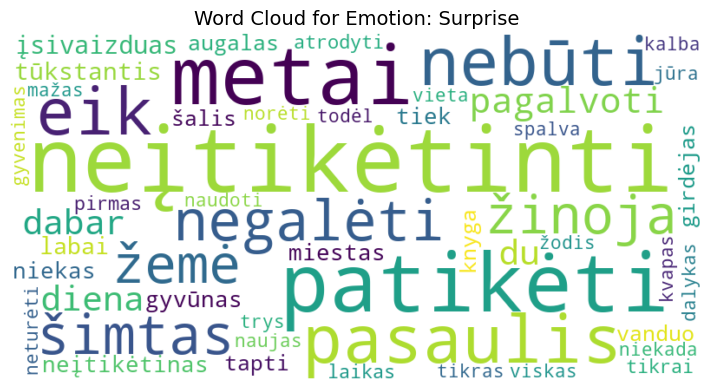


--- POS Distribution for Emotion: Anger ---
[('NOUN', 46480), ('VERB', 41016), ('PRON', 31538), ('ADV', 19718), ('ADJ', 11438), ('PART', 11242), ('DET', 10254), ('ADP', 10031), ('CCONJ', 9862), ('SCONJ', 8654), ('X', 3103), ('AUX', 1827), ('NUM', 1182), ('PROPN', 633), ('INTJ', 45), ('SYM', 44), ('PUNCT', 37), ('SPACE', 7)]

--- POS Distribution for Emotion: Joy ---
[('NOUN', 57040), ('VERB', 30124), ('ADJ', 17310), ('PRON', 15085), ('ADV', 12104), ('CCONJ', 11233), ('DET', 9097), ('ADP', 8154), ('SCONJ', 5879), ('PART', 5854), ('AUX', 2914), ('X', 1886), ('NUM', 944), ('PROPN', 698), ('INTJ', 26), ('SYM', 25), ('PUNCT', 7)]

--- POS Distribution for Emotion: Neutral ---
[('NOUN', 82586), ('VERB', 46928), ('ADJ', 19796), ('ADV', 16729), ('PRON', 13480), ('CCONJ', 12030), ('ADP', 10875), ('DET', 9171), ('PART', 7957), ('SCONJ', 7215), ('AUX', 4686), ('X', 3343), ('NUM', 2474), ('PROPN', 2432), ('SYM', 64), ('INTJ', 17), ('PUNCT', 12)]

--- POS Distribution for Emotion: Sadness ---
[('N

<Figure size 1000x600 with 0 Axes>

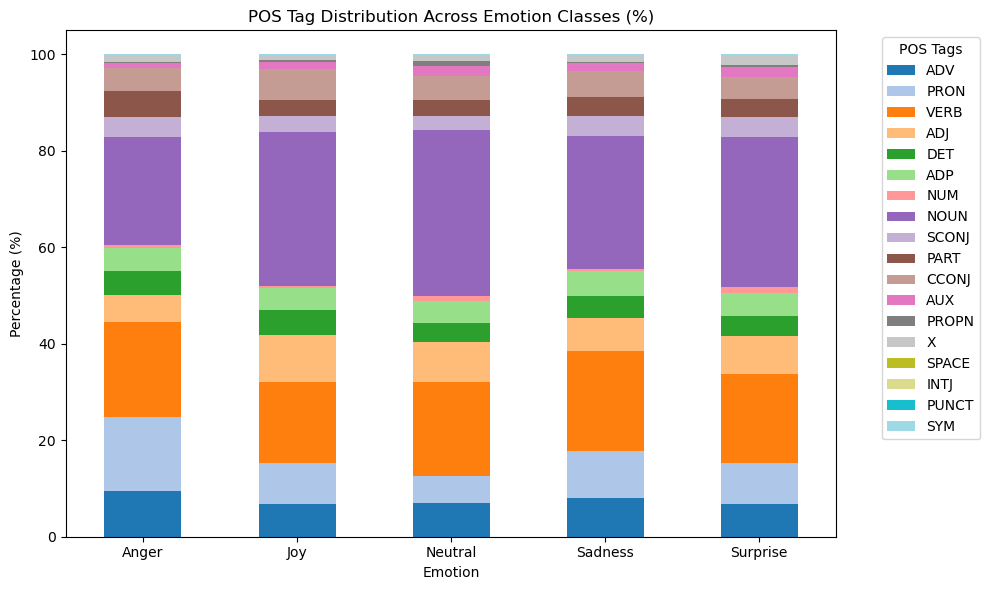

In [2]:
df = pd.read_csv("emo_text_dataset.csv")
nlp = spacy.load("lt_core_news_sm", disable=["parser", "ner"])
nlp.Defaults.stop_words |= {"būti", "galėti", "turėti", "reikėti", "daug", "žmogus", "čia"}
for w in nlp.Defaults.stop_words:
    nlp.vocab[w].is_stop = True

#Text length analysis
df["Word_Count"] = df["Text"].str.split().str.len()
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x="Word_Count", hue="Emotion", fill=True, common_norm=False, alpha=0.3)
plt.title("Distribution of Text Lengths Across Emotion Classes")
plt.xlabel("Text Length (in words)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#Vocabulary analysis
df["Tokens"] = [
    [
        token.lemma_.lower()
        for token in doc
        if token.is_alpha and not token.is_stop and not nlp.vocab[token.lemma_].is_stop and len(token.text) > 1
    ]
    for doc in nlp.pipe(df["Text"].astype(str), batch_size=1000)
]

emotions = sorted(df["Emotion"].unique())
emotion_word_freq = {}

for emotion in emotions:
    all_tokens = [
        token
        for tokens_list in df.loc[df["Emotion"] == emotion, "Tokens"]
        for token in tokens_list
    ]
    word_counts = Counter(all_tokens)
    emotion_word_freq[emotion] = word_counts

    print(f"\n--- Top 10 Most Frequent Words for Emotion: {emotion} ---")
    print(word_counts.most_common(10))

for emotion in emotions:
    wc = WordCloud(
        width=800,
        height=400,
        background_color="white",
        colormap="viridis",
        max_words=50,
        random_state=123
    ).generate_from_frequencies(emotion_word_freq[emotion])
    
    plt.figure(figsize=(8, 4))
    plt.imshow(wc, interpolation="bilinear")
    plt.title(f"Word Cloud for Emotion: {emotion}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

#Part-of-speech (POS) analysis
df["POS"] = [
    [
        token.pos_
        for token in doc
        if not token.is_space and not token.is_punct
    ]
    for doc in nlp.pipe(df["Text"].astype(str), batch_size=1000)
]

emotion_pos_freq = {}
for emotion in emotions:
    all_pos = [
        pos
        for pos_list in df.loc[df["Emotion"] == emotion, "POS"]
        for pos in pos_list
    ]
    pos_counts = Counter(all_pos)
    emotion_pos_freq[emotion] = pos_counts

    print(f"\n--- POS Distribution for Emotion: {emotion} ---")
    print(pos_counts.most_common())

pos_df = pd.DataFrame(emotion_pos_freq).fillna(0).T
pos_df_norm = pos_df.div(pos_df.sum(axis=1), axis=0) * 100

plt.figure(figsize=(10, 6))
pos_df_norm.plot(kind="bar", stacked=True, figsize=(10, 6), colormap="tab20")
plt.title("POS Tag Distribution Across Emotion Classes (%)")
plt.xlabel("Emotion")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="POS Tags", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [3]:
#Feature extraction
df["Cleaned_Text"] = df["Tokens"].apply(lambda tokens: " ".join(tokens))

X_train, X_test, y_train, y_test = train_test_split(
    df["Text"], 
    df["Emotion"], 
    test_size=0.2, 
    random_state=123, 
    stratify=df["Emotion"]
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print("\nClass distribution in training set (proportions):")
print(y_train.value_counts(normalize=True))

train_tokens = df.loc[X_train.index, "Tokens"]
unique_tokens = set(token for tokens_list in train_tokens for token in tokens_list)
print(f"Total unique words/lemmas in training set: {len(unique_tokens)}")

#TF-IDF
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf_vectorizer.fit_transform(df.loc[X_train.index, "Cleaned_Text"])
X_test_tfidf = tfidf_vectorizer.transform(df.loc[X_test.index, "Cleaned_Text"])

print(f"TF-IDF Train Shape: {X_train_tfidf.shape}")
print(f"TF-IDF Test Shape: {X_test_tfidf.shape}")

#FastText
ft_model = FastText(
    sentences=train_tokens, 
    vector_size=100,
    window=5,
    min_count=2,
    seed=123,
    epochs = 20,
    workers = 1
)

def get_avg_ft(tokens_list, model, vector_size=100):
    vectors = [model.wv[token] for token in tokens_list if token in model.wv]
    if not vectors:
        return np.zeros(vector_size)
    return np.mean(vectors, axis=0)

X_train_ft = np.array([get_avg_ft(tokens, ft_model) for tokens in train_tokens])
test_tokens = df.loc[X_test.index, "Tokens"]
X_test_ft = np.array([get_avg_ft(tokens, ft_model) for tokens in test_tokens])

print(f"FastText Train Shape: {X_train_ft.shape}")
print(f"FastText Test Shape: {X_test_ft.shape}")

#Sentence-BERT
sbert_model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
X_train_sbert = sbert_model.encode(X_train.tolist(), show_progress_bar=True)
X_test_sbert = sbert_model.encode(X_test.tolist(), show_progress_bar=True)

print(f"SBERT Train Shape: {X_train_sbert.shape}")
print(f"SBERT Test Shape: {X_test_sbert.shape}")

def get_sparsity(matrix):
    if hasattr(matrix, "toarray"):
        dense = matrix.toarray()
    else:
        dense = matrix
    return 1.0 - (np.count_nonzero(dense) / dense.size)

print("\n--- Representation Comparison Summary ---")
print(f"1. TF-IDF -> Shape (Dimensionality): {X_train_tfidf.shape[1]} | Sparsity: {get_sparsity(X_train_tfidf):.4f}")
print(f"2. FastText -> Shape (Dimensionality): {X_train_ft.shape[1]} | Sparsity: {get_sparsity(X_train_ft):.4f}")
print(f"3. SBERT -> Shape (Dimensionality): {X_train_sbert.shape[1]} | Sparsity: {get_sparsity(X_train_sbert):.4f}")

Training set shape: (107960,)
Test set shape: (26991,)

Class distribution in training set (proportions):
Emotion
Neutral     0.229576
Anger       0.207901
Sadness     0.197758
Joy         0.185235
Surprise    0.179529
Name: proportion, dtype: float64
Total unique words/lemmas in training set: 41992
TF-IDF Train Shape: (107960, 5000)
TF-IDF Test Shape: (26991, 5000)


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


FastText Train Shape: (107960, 100)
FastText Test Shape: (26991, 100)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/3374 [00:00<?, ?it/s]

Batches:   0%|          | 0/844 [00:00<?, ?it/s]

SBERT Train Shape: (107960, 384)
SBERT Test Shape: (26991, 384)

--- Representation Comparison Summary ---
1. TF-IDF -> Shape (Dimensionality): 5000 | Sparsity: 0.9994
2. FastText -> Shape (Dimensionality): 100 | Sparsity: 0.0094
3. SBERT -> Shape (Dimensionality): 384 | Sparsity: 0.0000


Training Logistic Regression on TF-IDF
Training Logistic Regression on FastText
Training Logistic Regression on SBERT

--- Comparative Classification Table ---
Representation  Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)
        TF-IDF  0.710904           0.721175        0.707011          0.709804
      FastText  0.546034           0.545549        0.541226          0.541259
         SBERT  0.624023           0.625448        0.619745          0.621307


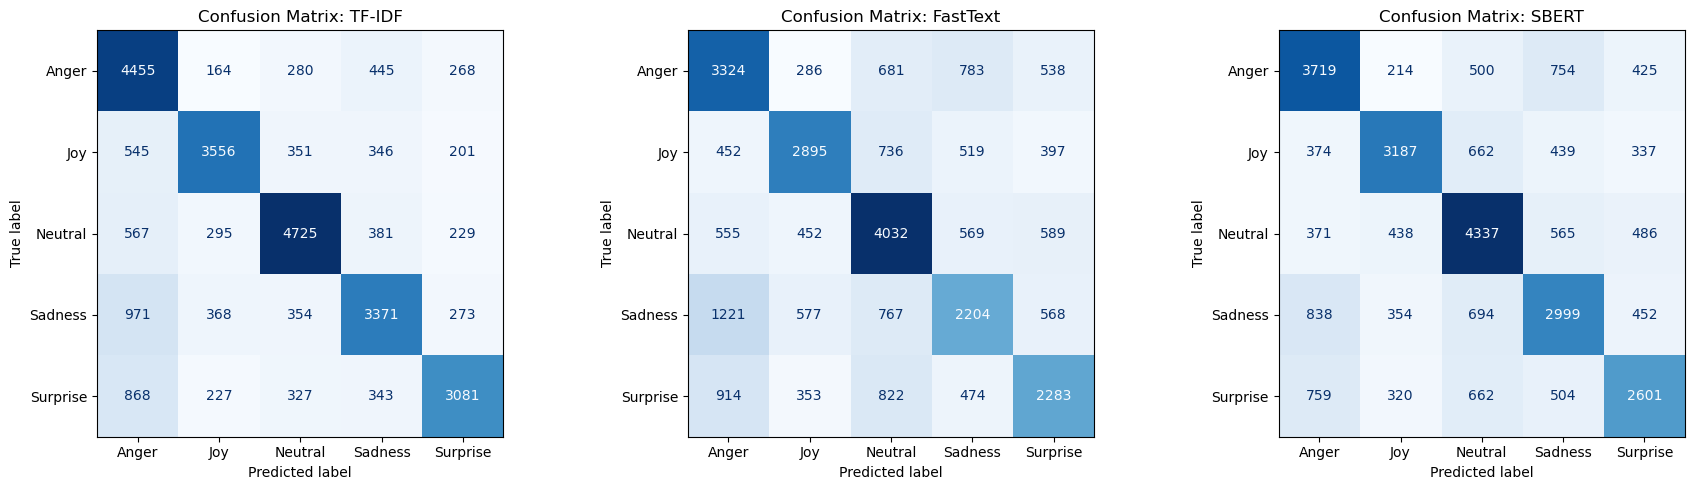

In [4]:
#Classification using Logistic Regression
representations = {
    "TF-IDF": (X_train_tfidf, X_test_tfidf),
    "FastText": (X_train_ft, X_test_ft),
    "SBERT": (X_train_sbert, X_test_sbert)
}

results = []
trained_models = {}

for name, (X_tr, X_te) in representations.items():
    print(f"Training Logistic Regression on {name}")
    clf = LogisticRegression(max_iter=1000, random_state=123)
    clf.fit(X_tr, y_train)
    trained_models[name] = clf
    
    y_pred = clf.predict(X_te)
    acc = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
    
    results.append({
        "Representation": name,
        "Accuracy": acc,
        "Precision (Macro)": precision,
        "Recall (Macro)": recall,
        "F1-Score (Macro)": f1
    })

results_df = pd.DataFrame(results)
print("\n--- Comparative Classification Table ---")
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (name, clf) in enumerate(trained_models.items()):
    X_te = representations[name][1]
    y_pred = clf.predict(X_te)  
    cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)    
    disp.plot(ax=axes[i], cmap="Blues", colorbar=False, xticks_rotation=0)
    axes[i].set_title(f"Confusion Matrix: {name}")
plt.tight_layout()
plt.show()